# Logistic Regression and Baselines for Missense Variant Classification

**DATA 245 Machine Learning, Group 8. Sharan Patil**

This notebook covers my part of the group project: regularized Logistic Regression plus two reference baselines
(majority class and conservation-only). I run them on feature sets A, B and D under both validation schemes, then look at
the coefficients to see what the model leans on.

Ground rules agreed by the team, and followed here:

1. Every model is evaluated on the shared `fold_assignments.csv` (standard and gene-disjoint folds, 3 repeats x 5 folds). No new train/test splits.
2. Imputation, scaling and tuning are fit on each fold's training rows only.
3. `pred_label = 1` when `p_pathogenic >= 0.5`, so MCC, sensitivity and specificity line up across models.
4. Predictions are saved with the columns `model, feature_set, validation, repeat, fold, VariationID, label, p_pathogenic, pred_label`.

Inputs come from `data/processed/` and the team's shared `fold_assignments.csv`. Everything this notebook writes goes to
`results/logistic_regression/`. The prediction files are gzipped CSVs (`pd.read_csv` opens them directly).

Runtime: about 25 minutes on a 2-core laptop CPU for the main run. No GPU needed. Finished folds are cached in
`results/logistic_regression/cache/` (not committed), so a rerun only fits the folds that are missing.

## 1. Setup

In [1]:
import json, pickle, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             matthews_corrcoef, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="A worker stopped")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

def find_repo_root():
    # works whether this runs from the repo root, from notebooks/ or from src/models/
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "processed" / "clinvar_expanded_model_features.csv").exists():
            return p
    raise FileNotFoundError("could not find data/processed/clinvar_expanded_model_features.csv")


ROOT = find_repo_root()
DATA_DIR = ROOT / "data" / "processed"
FEATURES_CSV = DATA_DIR / "clinvar_expanded_model_features.csv"
CONFIG_JSON = DATA_DIR / "feature_config.json"
PROJECT_CSV = DATA_DIR / "clinvar_expanded_project_dataset.csv"   # only used for the published-tool comparison
# the team's shared fold file
FOLDS_CSV = next(p for p in [DATA_DIR / "fold_assignments.csv",
                             ROOT / "results" / "gaussian_mixture" / "fold_assignments.csv"] if p.exists())

RESULTS = ROOT / "results" / "logistic_regression"
CACHE = RESULTS / "cache"
FIGS = RESULTS / "figures"
for p in (RESULTS, CACHE / "main", CACHE / "tuned", FIGS):
    p.mkdir(parents=True, exist_ok=True)

SEED = 245
THRESHOLD = 0.5
FEATURE_SETS = ["A", "B", "D"]
INNER_FOLDS = 3
N_JOBS = -1   # use all CPU cores

## 2. Load the shared data and folds

In [2]:
data = pd.read_csv(FEATURES_CSV)
cfg = json.load(open(CONFIG_JSON))
folds = pd.read_csv(FOLDS_CSV)

print("data:", DATA_DIR.relative_to(ROOT), "| folds:", FOLDS_CSV.relative_to(ROOT))
print(f"{len(data):,} variants, {data.GeneSymbol.nunique():,} genes")
print(data.label.value_counts().rename({0: "benign", 1: "pathogenic"}).to_string())
print(f"pathogenic share: {data.label.mean():.3f}")
for k, v in cfg["feature_sets"].items():
    print(f"feature set {k}: {len(v)} features")

missing = data[cfg["feature_sets"]["D"]].isna().sum()
print("\nmissing values:")
print(missing[missing > 0].to_string())

data: data/processed | folds: results/gaussian_mixture/fold_assignments.csv
46,012 variants, 2,105 genes
label
benign        32013
pathogenic    13999
pathogenic share: 0.304
feature set A: 6 features
feature set B: 15 features
feature set D: 28 features

missing values:
gnomADe_AF              1051
gnomADe_AF_neglog10     1051
gnomADg_AF             12600
gnomADg_AF_neglog10    12600


In [3]:
# checks on the shared files before using them
assert data.VariationID.is_unique
assert set(data.VariationID) == set(folds.VariationID)
gd = folds[folds.validation == "gene_disjoint"]
assert gd.groupby(["repeat", "GeneSymbol"]).test_fold.nunique().max() == 1, "a gene is split across folds"
assert (folds.groupby(["validation", "repeat"]).VariationID.nunique() == len(data)).all()

folds.groupby(["validation", "repeat", "test_fold"]).size().unstack()

test_fold                 0     1     2     3     4
validation    repeat                               
gene_disjoint 0        9092  9684  8970  9197  9069
              1       10147  9715  8891  7979  9280
              2        8673  9379  9311  8678  9971
standard      0        9203  9203  9202  9202  9202
              1        9203  9203  9202  9202  9202
              2        9203  9203  9202  9202  9202

## 3. Models

**Logistic Regression.** Median imputation, standard scaling, then Logistic Regression with balanced class weights,
all inside one pipeline so nothing is fit on test rows. The penalty is tuned by an inner 3-fold CV on the outer training
rows only, scored by PR-AUC. For the gene-disjoint scheme the inner folds are grouped by gene too.

Grid: L2 with C from 1e-3 to 1e2, and elastic net (saga) with C from 1e-3 to 1 and l1_ratio in {0.2, 0.5, 0.8}.
Elastic net stops at C = 1 because with roughly 37,000 training rows the penalty is negligible above that, and L2
already covers the range.

**Majority class.** Predicts the training prevalence (about 0.30) for every variant, so `pred_label` is always 0.

**Conservation-only.** Picks the single conservation track that ranks best on the training rows, then maps it to a
probability with a one-variable, class-balanced logistic fit. The ranking is the raw track's, so its ROC-AUC and PR-AUC
are the track's own, and p = 0.5 is the training-chosen cut-off.

In [4]:
C_GRID = [1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2]
EN_C_GRID = [1e-3, 1e-2, 1e-1, 1e0]
L1_RATIOS = [0.2, 0.5, 0.8]
PARAM_GRID = [
    {"lr__solver": ["lbfgs"], "lr__l1_ratio": [0.0], "lr__C": C_GRID},
    {"lr__solver": ["saga"], "lr__l1_ratio": L1_RATIOS, "lr__C": EN_C_GRID},
]


def make_lr_pipeline():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(class_weight="balanced", max_iter=5000, tol=1e-4, random_state=SEED)),
    ])


def make_cons_pipeline():
    return Pipeline([("scale", StandardScaler()),
                     ("lr", LogisticRegression(class_weight="balanced", C=1e6, max_iter=1000))])


def inner_cv(validation, repeat, fold):
    seed = SEED + 100 * repeat + fold
    if validation == "gene_disjoint":
        return StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=seed)
    return StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=seed)


def pred_frame(model, feature_set, validation, repeat, fold, test, p):
    return pd.DataFrame({
        "model": model, "feature_set": feature_set, "validation": validation,
        "repeat": repeat, "fold": fold,
        "VariationID": test["VariationID"].values, "label": test["label"].values,
        "p_pathogenic": p, "pred_label": (p >= THRESHOLD).astype(int),
    })


def run_one_fold(df, validation, repeat, fold):
    warnings.filterwarnings("ignore")
    is_test = df["test_fold"].values == fold
    train, test = df[~is_test], df[is_test]
    y_tr = train["label"].values
    preds, info, coefs = [], [], []
    base = {"validation": validation, "repeat": repeat, "fold": fold,
            "n_train": len(train), "n_test": len(test),
            "genes_train": train.GeneSymbol.nunique(), "genes_test": test.GeneSymbol.nunique(),
            "genes_shared": len(set(train.GeneSymbol) & set(test.GeneSymbol)),
            "pathogenic_rate_train": y_tr.mean(), "pathogenic_rate_test": test.label.mean()}

    # majority class
    prev = y_tr.mean()
    preds.append(pred_frame("Majority", "none", validation, repeat, fold, test, np.full(len(test), prev)))
    info.append({**base, "model": "Majority", "feature_set": "none", "detail": f"train prevalence={prev:.4f}"})

    # conservation-only
    tracks = cfg["feature_groups"]["conservation"]
    aucs = {t: roc_auc_score(y_tr, train[t].values) for t in tracks}
    best = max(aucs, key=lambda t: max(aucs[t], 1 - aucs[t]))
    cons = make_cons_pipeline().fit(train[[best]].values, y_tr)
    p_cons = cons.predict_proba(test[[best]].values)[:, 1]
    sc, lr = cons.named_steps["scale"], cons.named_steps["lr"]
    raw_cut = sc.mean_[0] - lr.intercept_[0] / lr.coef_[0, 0] * sc.scale_[0]
    preds.append(pred_frame("ConservationOnly", "A", validation, repeat, fold, test, p_cons))
    info.append({**base, "model": "ConservationOnly", "feature_set": "A", "chosen_track": best,
                 "track_train_auc": aucs[best], "raw_threshold": raw_cut})

    # Logistic Regression, nested tuning
    groups = train["GeneSymbol"].values
    for fs in FEATURE_SETS:
        cols = cfg["feature_sets"][fs]
        t0 = time.time()
        search = GridSearchCV(make_lr_pipeline(), PARAM_GRID, scoring="average_precision",
                              cv=inner_cv(validation, repeat, fold), n_jobs=1, refit=True)
        if validation == "gene_disjoint":
            search.fit(train[cols], y_tr, groups=groups)
        else:
            search.fit(train[cols], y_tr)
        p_lr = search.predict_proba(test[cols])[:, 1]
        best_lr = search.best_estimator_.named_steps["lr"]
        bp = search.best_params_
        preds.append(pred_frame("LogisticRegression", fs, validation, repeat, fold, test, p_lr))
        info.append({**base, "model": "LogisticRegression", "feature_set": fs,
                     "best_penalty": "l2" if bp["lr__l1_ratio"] == 0 else "elasticnet",
                     "best_C": bp["lr__C"], "best_l1_ratio": bp["lr__l1_ratio"],
                     "inner_pr_auc": search.best_score_, "n_iter": int(best_lr.n_iter_[0]),
                     "fit_seconds": time.time() - t0})
        for name, w in zip(cols, best_lr.coef_[0]):
            coefs.append({"validation": validation, "repeat": repeat, "fold": fold,
                          "feature_set": fs, "feature": name, "coef": w})
        coefs.append({"validation": validation, "repeat": repeat, "fold": fold,
                      "feature_set": fs, "feature": "(intercept)", "coef": best_lr.intercept_[0]})
    return pd.concat(preds, ignore_index=True), pd.DataFrame(info), pd.DataFrame(coefs)

## 4. Run all 30 outer folds (2 schemes x 3 repeats x 5 folds)

In [5]:
fold_frames = {}
jobs = []
for (validation, repeat), part in folds.groupby(["validation", "repeat"]):
    merged = data.merge(part[["VariationID", "test_fold"]], on="VariationID")
    fold_frames[(validation, repeat)] = merged
    for fold in sorted(part.test_fold.unique()):
        path = CACHE / "main" / f"{validation}_r{repeat}_f{fold}.pkl"
        if not path.exists():
            jobs.append((validation, int(repeat), int(fold), path))

print(f"{len(jobs)} of 30 outer folds still to fit")


def work(validation, repeat, fold, path):
    res = run_one_fold(fold_frames[(validation, repeat)], validation, repeat, fold)
    pickle.dump(res, open(path, "wb"))
    return f"{validation} repeat {repeat} fold {fold} done"


t0 = time.time()
for msg in Parallel(n_jobs=N_JOBS, return_as="generator")(delayed(work)(*j) for j in jobs):
    print(msg)
print(f"finished in {(time.time() - t0) / 60:.1f} min")

0 of 30 outer folds still to fit
finished in 0.0 min


In [6]:
parts = [pickle.load(open(f, "rb")) for f in sorted((CACHE / "main").glob("*.pkl"))]
preds = pd.concat([p for p, _, _ in parts], ignore_index=True)
details = pd.concat([i for _, i, _ in parts], ignore_index=True)
coefs = pd.concat([c for _, _, c in parts], ignore_index=True)

preds = preds.sort_values(["model", "feature_set", "validation", "repeat", "fold", "VariationID"])
preds.to_csv(RESULTS / "sharan_lr_baseline_predictions.csv.gz", index=False)
details.to_csv(RESULTS / "fold_details.csv", index=False)
coefs.to_csv(RESULTS / "lr_coefficients_per_fold.csv", index=False)

# format checks on the shared prediction file
assert list(preds.columns) == ["model", "feature_set", "validation", "repeat", "fold",
                               "VariationID", "label", "p_pathogenic", "pred_label"]
assert ((preds.p_pathogenic >= THRESHOLD).astype(int) == preds.pred_label).all()
assert (preds.groupby(["model", "feature_set", "validation", "repeat"]).VariationID.nunique() == len(data)).all()
print(f"{len(preds):,} prediction rows saved")
preds.groupby(["model", "feature_set", "validation"]).size()

1,380,360 prediction rows saved


model               feature_set  validation   
ConservationOnly    A            gene_disjoint    138036
                                 standard         138036
LogisticRegression  A            gene_disjoint    138036
                                 standard         138036
                    B            gene_disjoint    138036
                                 standard         138036
                    D            gene_disjoint    138036
                                 standard         138036
Majority            none         gene_disjoint    138036
                                 standard         138036
dtype: int64

## 5. Metrics per fold and summary

In [7]:
KEYS = ["model", "feature_set", "validation", "repeat", "fold"]


def fold_metrics(g):
    y, p, yhat = g.label.values, g.p_pathogenic.values, g.pred_label.values
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    return pd.Series({"n_test": len(y), "prevalence": y.mean(),
                      "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
                      "mcc": matthews_corrcoef(y, yhat), "sensitivity": sens, "specificity": spec,
                      "accuracy": (tp + tn) / len(y), "balanced_accuracy": (sens + spec) / 2,
                      "brier": brier_score_loss(y, p)})


fm = preds.groupby(KEYS).apply(fold_metrics, include_groups=False).reset_index()
fm = fm.merge(details[["validation", "repeat", "fold", "n_train"]].drop_duplicates(),
              on=["validation", "repeat", "fold"])
fm.to_csv(RESULTS / "fold_metrics.csv", index=False)

METRICS = ["roc_auc", "pr_auc", "mcc", "sensitivity", "specificity", "accuracy", "balanced_accuracy", "brier"]
summ = fm.groupby(["validation", "model", "feature_set"])[METRICS].agg(["mean", "std"])
summ.columns = [f"{m}_{s}" for m, s in summ.columns]
summ = summ.reset_index()
order = {"Majority": 0, "ConservationOnly": 1, "LogisticRegression": 2}
summ = summ.sort_values(["validation", "model", "feature_set"],
                        key=lambda s: s.map(order) if s.name == "model" else s,
                        ascending=[False, True, True]).reset_index(drop=True)
summ.to_csv(RESULTS / "summary_metrics.csv", index=False)


def pm(df, m):
    return df[f"{m}_mean"].map("{:.3f}".format) + " ± " + df[f"{m}_std"].map("{:.3f}".format)


view = summ[["validation", "model", "feature_set"]].copy()
for m in ["roc_auc", "pr_auc", "mcc", "sensitivity", "specificity", "accuracy"]:
    view[m] = pm(summ, m)
view

,validation,model,feature_set,roc_auc,pr_auc,mcc,sensitivity,specificity,accuracy
0,standard,Majority,none,0.500 ± 0.000,0.304 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.696 ± 0.000
1,standard,ConservationOnly,A,0.792 ± 0.004,0.584 ± 0.006,0.428 ± 0.008,0.739 ± 0.008,0.719 ± 0.004,0.725 ± 0.004
2,standard,LogisticRegression,A,0.797 ± 0.004,0.592 ± 0.006,0.425 ± 0.006,0.775 ± 0.007,0.685 ± 0.005,0.712 ± 0.003
3,standard,LogisticRegression,B,0.861 ± 0.003,0.720 ± 0.006,0.520 ± 0.006,0.821 ± 0.006,0.738 ± 0.006,0.764 ± 0.003
4,standard,LogisticRegression,D,0.891 ± 0.003,0.772 ± 0.007,0.587 ± 0.006,0.844 ± 0.007,0.783 ± 0.006,0.801 ± 0.004
5,gene_disjoint,Majority,none,0.500 ± 0.000,0.305 ± 0.032,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.695 ± 0.032
6,gene_disjoint,ConservationOnly,A,0.792 ± 0.012,0.584 ± 0.046,0.427 ± 0.026,0.739 ± 0.017,0.720 ± 0.017,0.725 ± 0.012
7,gene_disjoint,LogisticRegression,A,0.796 ± 0.013,0.588 ± 0.048,0.423 ± 0.028,0.774 ± 0.017,0.685 ± 0.018,0.712 ± 0.014
8,gene_disjoint,LogisticRegression,B,0.861 ± 0.010,0.718 ± 0.041,0.519 ± 0.033,0.820 ± 0.018,0.738 ± 0.028,0.763 ± 0.019
9,gene_disjoint,LogisticRegression,D,0.891 ± 0.007,0.770 ± 0.037,0.585 ± 0.028,0.844 ± 0.015,0.782 ± 0.021,0.800 ± 0.014


## 6. Paired comparisons (H1) and the population-frequency gain (H2)

Comparisons are paired by fold within a scheme. Repeated CV folds overlap, so a plain t-test would be too optimistic.
I use the Nadeau and Bengio corrected resampled t-test, which inflates the variance by the test/train size ratio.

In [8]:
def corrected_ttest(d, n_train, n_test):
    d = np.asarray(d, float)
    k, var = len(d), d.var(ddof=1)
    if var == 0:
        return np.nan, np.nan
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * var)
    return t, 2 * stats.t.sf(abs(t), df=k - 1)


def scores(model, fs, val):
    s = fm[(fm.model == model) & (fm.feature_set == fs) & (fm.validation == val)]
    return s.set_index(["repeat", "fold"]).sort_index()


pairs = [("LR B vs LR A", ("LogisticRegression", "B"), ("LogisticRegression", "A")),
         ("LR D vs LR B", ("LogisticRegression", "D"), ("LogisticRegression", "B")),
         ("LR D vs LR A", ("LogisticRegression", "D"), ("LogisticRegression", "A")),
         ("LR A vs ConservationOnly", ("LogisticRegression", "A"), ("ConservationOnly", "A")),
         ("ConservationOnly vs Majority", ("ConservationOnly", "A"), ("Majority", "none"))]
rows = []
for val in ["standard", "gene_disjoint"]:
    for name, a, b in pairs:
        sa, sb = scores(*a, val), scores(*b, val)
        for m in ["roc_auc", "pr_auc", "mcc"]:
            d = (sa[m] - sb[m]).values
            t, p = corrected_ttest(d, sa.n_train.mean(), sa.n_test.mean())
            rows.append({"validation": val, "comparison": name, "metric": m, "mean_delta": d.mean(),
                         "sd_delta": d.std(ddof=1), "folds_improved": f"{(d > 0).sum()}/{len(d)}",
                         "corrected_t": t, "p_value": p})
paired = pd.DataFrame(rows)
paired.to_csv(RESULTS / "paired_comparisons.csv", index=False)
paired[paired.metric == "pr_auc"].round(4)

,validation,comparison,metric,mean_delta,sd_delta,folds_improved,corrected_t,p_value
1,standard,LR B vs LR A,pr_auc,0.1286,0.0055,15/15,41.3212,0.0000
4,standard,LR D vs LR B,pr_auc,0.0518,0.0053,15/15,17.2960,0.0000
7,standard,LR D vs LR A,pr_auc,0.1804,0.0075,15/15,42.5861,0.0000
10,standard,LR A vs ConservationOnly,pr_auc,0.0072,0.0022,15/15,5.7345,0.0001
13,standard,ConservationOnly vs Majority,pr_auc,0.2801,0.0060,15/15,83.4506,0.0000
16,gene_disjoint,LR B vs LR A,pr_auc,0.1299,0.0166,15/15,13.8684,0.0000
19,gene_disjoint,LR D vs LR B,pr_auc,0.0514,0.0093,15/15,9.7906,0.0000
22,gene_disjoint,LR D vs LR A,pr_auc,0.1813,0.0220,15/15,14.6650,0.0000
25,gene_disjoint,LR A vs ConservationOnly,pr_auc,0.0043,0.0062,13/15,1.2387,0.2358
28,gene_disjoint,ConservationOnly vs Majority,pr_auc,0.2792,0.0251,15/15,19.7332,0.0000


In [9]:
# H2: is the gain from population frequency (B - A) smaller on unseen genes?
h2 = []
for m in ["roc_auc", "pr_auc", "mcc"]:
    r = {"metric": m}
    for val in ["standard", "gene_disjoint"]:
        r[f"B_minus_A_{val}"] = paired.query("validation == @val and comparison == 'LR B vs LR A' and metric == @m").mean_delta.iloc[0]
    r["gain_retained_on_unseen_genes"] = r["B_minus_A_gene_disjoint"] / r["B_minus_A_standard"]
    h2.append(r)
h2 = pd.DataFrame(h2)
h2.to_csv(RESULTS / "h2_population_gain.csv", index=False)

gap = []
for (model, fs), g in fm.groupby(["model", "feature_set"]):
    for m in ["roc_auc", "pr_auc", "mcc"]:
        st, gd_ = g[g.validation == "standard"][m].mean(), g[g.validation == "gene_disjoint"][m].mean()
        gap.append({"model": model, "feature_set": fs, "metric": m, "standard_mean": st,
                    "gene_disjoint_mean": gd_, "gap": st - gd_})
gap = pd.DataFrame(gap)
gap.to_csv(RESULTS / "generalization_gap.csv", index=False)
display(h2.round(3))
gap[gap.metric == "pr_auc"].round(4)

,metric,B_minus_A_standard,B_minus_A_gene_disjoint,gain_retained_on_unseen_genes
0,roc_auc,0.064,0.065,1.011
1,pr_auc,0.129,0.130,1.010
2,mcc,0.095,0.096,1.007


,model,feature_set,metric,standard_mean,gene_disjoint_mean,gap
1,ConservationOnly,A,pr_auc,0.5844,0.5841,0.0003
4,LogisticRegression,A,pr_auc,0.5916,0.5885,0.0031
7,LogisticRegression,B,pr_auc,0.7202,0.7184,0.0018
10,LogisticRegression,D,pr_auc,0.7720,0.7698,0.0022
13,Majority,none,pr_auc,0.3042,0.3050,-0.0007


## 7. Hyperparameters chosen by the inner CV

In [10]:
tune = (details[details.model == "LogisticRegression"]
        .groupby(["validation", "feature_set", "best_penalty", "best_C", "best_l1_ratio"]).size()
        .rename("n_folds").reset_index())
tune.to_csv(RESULTS / "tuning_summary.csv", index=False)
print("conservation-only track picked:", details.chosen_track.dropna().value_counts().to_dict())
tune

conservation-only track picked: {'phyloP100way_vertebrate': 30}


,validation,feature_set,best_penalty,best_C,best_l1_ratio,n_folds
0,gene_disjoint,A,elasticnet,0.001,0.5,1
1,gene_disjoint,A,elasticnet,0.001,0.8,1
2,gene_disjoint,A,l2,0.010,0.0,13
3,gene_disjoint,B,elasticnet,1.000,0.8,3
4,gene_disjoint,B,l2,0.001,0.0,1
5,gene_disjoint,B,l2,10.000,0.0,3
6,gene_disjoint,B,l2,100.000,0.0,8
7,gene_disjoint,D,l2,1.000,0.0,2
8,gene_disjoint,D,l2,10.000,0.0,7
9,gene_disjoint,D,l2,100.000,0.0,6


## 8. Coefficient analysis

Features are standardized, so each weight is the change in log-odds of pathogenicity per one standard deviation.
The conservation tracks are strongly correlated, and so are the population columns (`gnomAD_AF` is almost a copy of
`gnomADe_AF`, and every `_neglog10` column mirrors its raw frequency). Single weights can trade off against each other,
so the family-level share of total |weight| is the main view. Sign stability is the share of the 15 folds that agree
on the sign.

In [11]:
fam_of = {f: fam for fam, cols in cfg["feature_groups"].items() for f in cols}
feat_order = [f for cols in cfg["feature_groups"].values() for f in cols]
cf = coefs[coefs.feature != "(intercept)"].copy()
cf["family"] = cf.feature.map(fam_of)

rows = []
for (val, fs, feat), g in cf.groupby(["validation", "feature_set", "feature"]):
    w = g.coef.values
    pos, neg = (w > 0).sum(), (w < 0).sum()
    rows.append({"validation": val, "feature_set": fs, "family": fam_of[feat], "feature": feat,
                 "mean_coef": w.mean(), "sd_coef": w.std(ddof=1), "min_coef": w.min(), "max_coef": w.max(),
                 "n_positive": pos, "n_negative": neg, "n_zero": (w == 0).sum(),
                 "sign_stability": max(pos, neg) / len(w)})
feat_df = pd.DataFrame(rows)
feat_df["_o"] = feat_df.feature.map(feat_order.index)
feat_df = feat_df.sort_values(["feature_set", "validation", "_o"], ascending=[True, False, True]).drop(columns="_o")
feat_df.to_csv(RESULTS / "coef_feature_summary.csv", index=False)

fam_fold = (cf.assign(abs_coef=cf.coef.abs())
            .groupby(["validation", "feature_set", "repeat", "fold", "family"]).abs_coef.sum()
            .rename("sum_abs_coef").reset_index())
fam_fold["share"] = fam_fold.sum_abs_coef / fam_fold.groupby(
    ["validation", "feature_set", "repeat", "fold"]).sum_abs_coef.transform("sum")
fam_sum = (fam_fold.groupby(["validation", "feature_set", "family"])
           .agg(sum_abs_mean=("sum_abs_coef", "mean"), sum_abs_sd=("sum_abs_coef", "std"),
                share_mean=("share", "mean"), share_sd=("share", "std")).reset_index())
fam_sum.to_csv(RESULTS / "coef_family_summary.csv", index=False)
fam_sum.round(3)

,validation,feature_set,family,sum_abs_mean,sum_abs_sd,share_mean,share_sd
0,gene_disjoint,A,conservation,1.621,0.156,1.000,0.000
1,gene_disjoint,B,conservation,1.806,0.158,0.221,0.072
2,gene_disjoint,B,population,6.922,1.774,0.779,0.072
3,gene_disjoint,D,amino_acid,4.141,0.115,0.319,0.015
4,gene_disjoint,D,conservation,1.975,0.119,0.152,0.010
5,gene_disjoint,D,population,6.886,0.586,0.529,0.022
6,standard,A,conservation,1.673,0.017,1.000,0.000
7,standard,B,conservation,1.832,0.032,0.203,0.017
8,standard,B,population,7.275,0.842,0.797,0.017
9,standard,D,amino_acid,4.144,0.085,0.325,0.011


In [12]:
# per-feature view for the full model (set D), standard vs gene-disjoint side by side
d = feat_df[feat_df.feature_set == "D"].pivot(index="feature", columns="validation",
                                                values=["mean_coef", "sd_coef", "sign_stability"])
d = d.loc[feat_order]
d.columns = [f"{a}_{b}" for a, b in d.columns]
d.round(3)

,mean_coef_gene_disjoint,mean_coef_standard,sd_coef_gene_disjoint,sd_coef_standard,sign_stability_gene_disjoint,sign_stability_standard
feature,,,,,,
phyloP17way_primate,0.124,0.124,0.027,0.012,1.000,1.000
phastCons17way_primate,-0.199,-0.199,0.033,0.009,1.000,1.000
phyloP470way_mammalian,-0.110,-0.111,0.042,0.012,1.000,1.000
phastCons470way_mammalian,0.168,0.168,0.024,0.016,1.000,1.000
phyloP100way_vertebrate,1.075,1.076,0.040,0.011,1.000,1.000
phastCons100way_vertebrate,0.299,0.299,0.015,0.017,1.000,1.000
gnomADe_AF,0.431,0.412,0.044,0.025,1.000,1.000
gnomADe_AF_missing,0.112,0.111,0.012,0.009,1.000,1.000
gnomADe_AF_neglog10,0.242,0.239,0.163,0.127,0.933,0.933


## 9. Figures

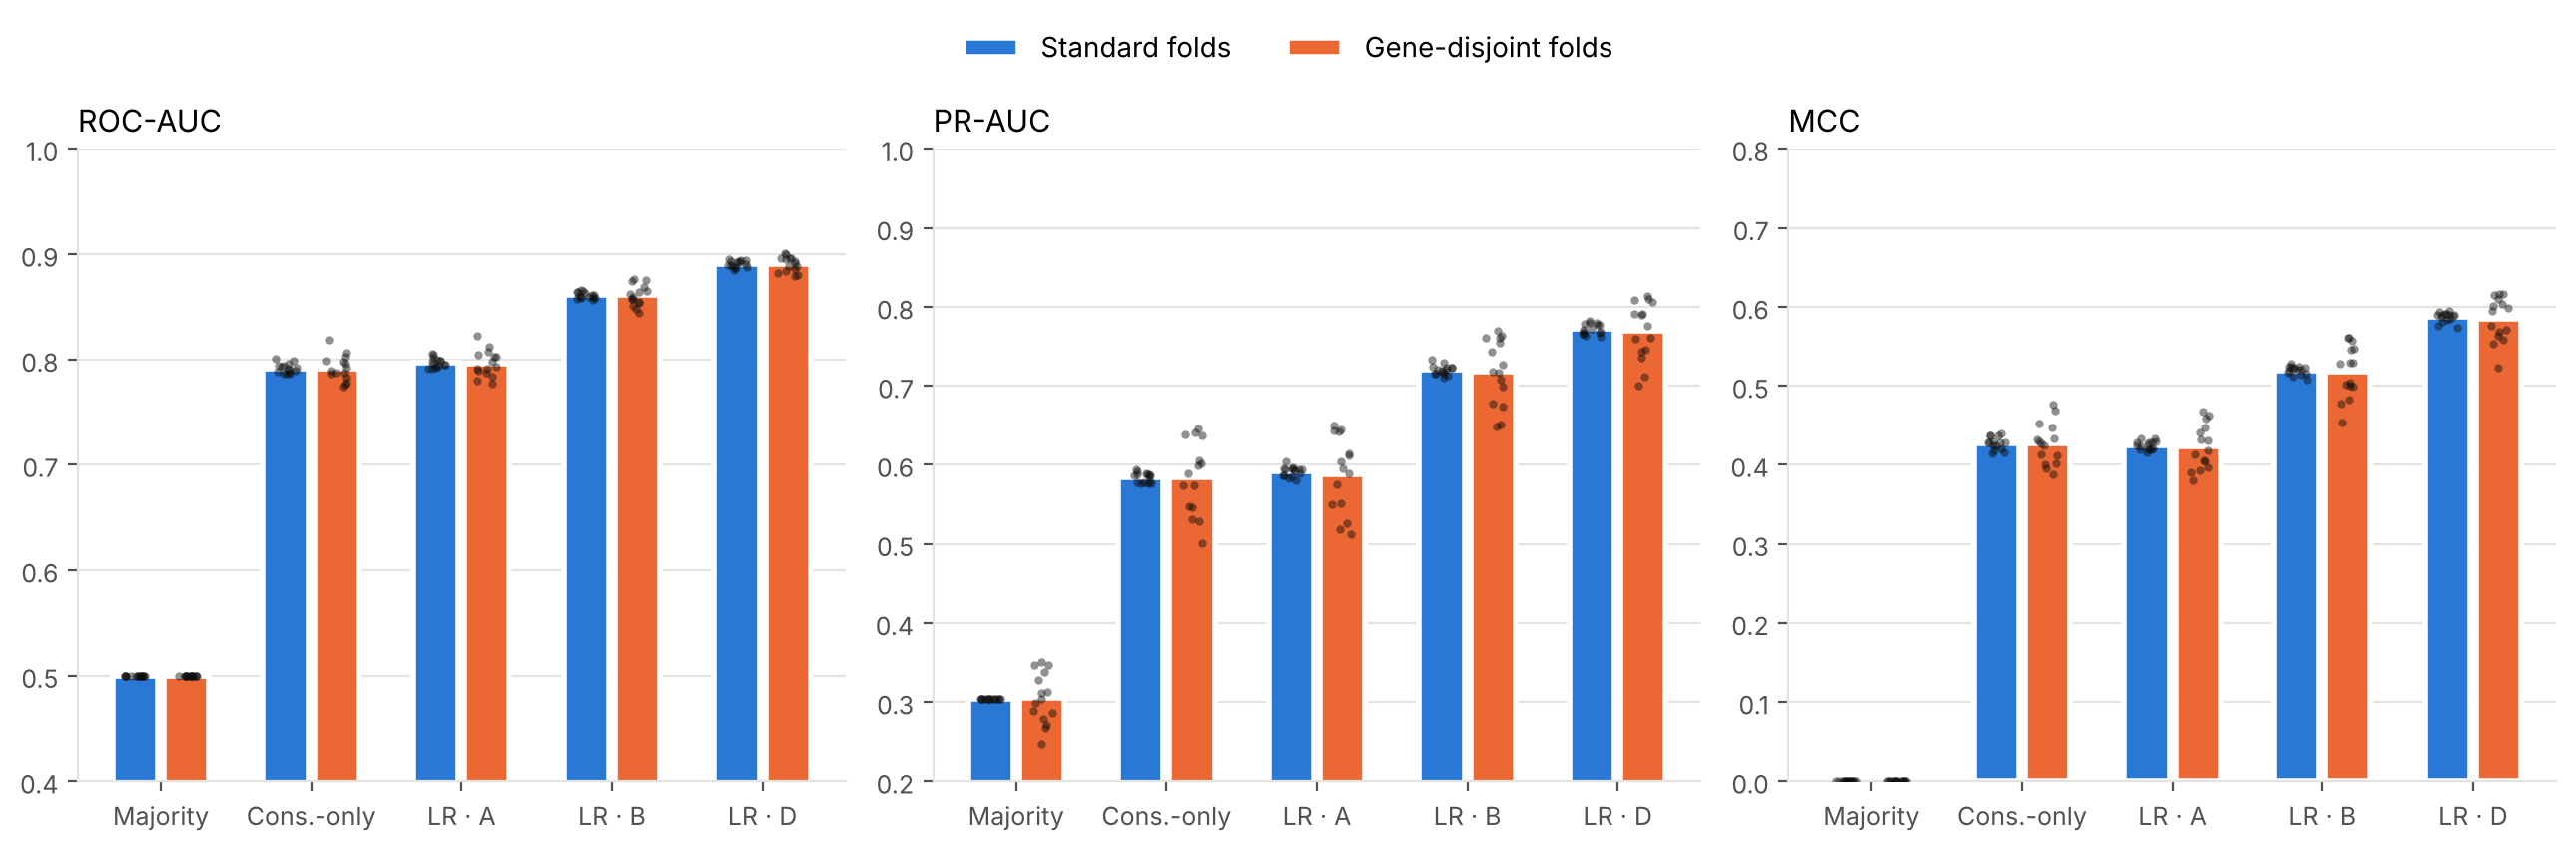

In [13]:
SCHEME_COLORS = {"standard": "#2a78d6", "gene_disjoint": "#eb6834"}
SCHEME_NAMES = {"standard": "Standard folds", "gene_disjoint": "Gene-disjoint folds"}
FAMILY_COLORS = {"conservation": "#2a78d6", "population": "#eb6834", "amino_acid": "#1baf7a"}
FAMILY_NAMES = {"conservation": "Conservation", "population": "Population frequency",
                "amino_acid": "Amino-acid properties"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
MODELS = [("Majority", "none", "Majority"), ("ConservationOnly", "A", "Cons.-only"),
          ("LogisticRegression", "A", "LR · A"), ("LogisticRegression", "B", "LR · B"),
          ("LogisticRegression", "D", "LR · D")]


def style(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=INK2, labelsize=9)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


# Figure 1: metrics by model, both schemes, one dot per fold
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
rng = np.random.default_rng(0)
for ax, (m, lab) in zip(axes, [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("mcc", "MCC")]):
    for j, val in enumerate(["standard", "gene_disjoint"]):
        for i, (mod, fs, _) in enumerate(MODELS):
            s = fm[(fm.model == mod) & (fm.feature_set == fs) & (fm.validation == val)][m]
            x = i + (j - 0.5) * 0.34
            ax.bar(x, s.mean(), width=0.3, color=SCHEME_COLORS[val], edgecolor="white", linewidth=2,
                   label=SCHEME_NAMES[val] if (i == 0 and m == "roc_auc") else None)
            ax.scatter(x + rng.uniform(-0.07, 0.07, len(s)), s, s=9, color=INK, alpha=0.45, zorder=3, linewidths=0)
    ax.set_xticks(range(len(MODELS)))
    ax.set_xticklabels([t for *_, t in MODELS], fontsize=9)
    ax.set_title(lab, fontsize=11, loc="left")
    ax.set_ylim({"roc_auc": 0.4, "pr_auc": 0.2, "mcc": 0}[m], 1 if m != "mcc" else 0.8)
    style(ax)
fig.legend(loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIGS / "fig1_metrics_by_model.png", dpi=200)
plt.show()

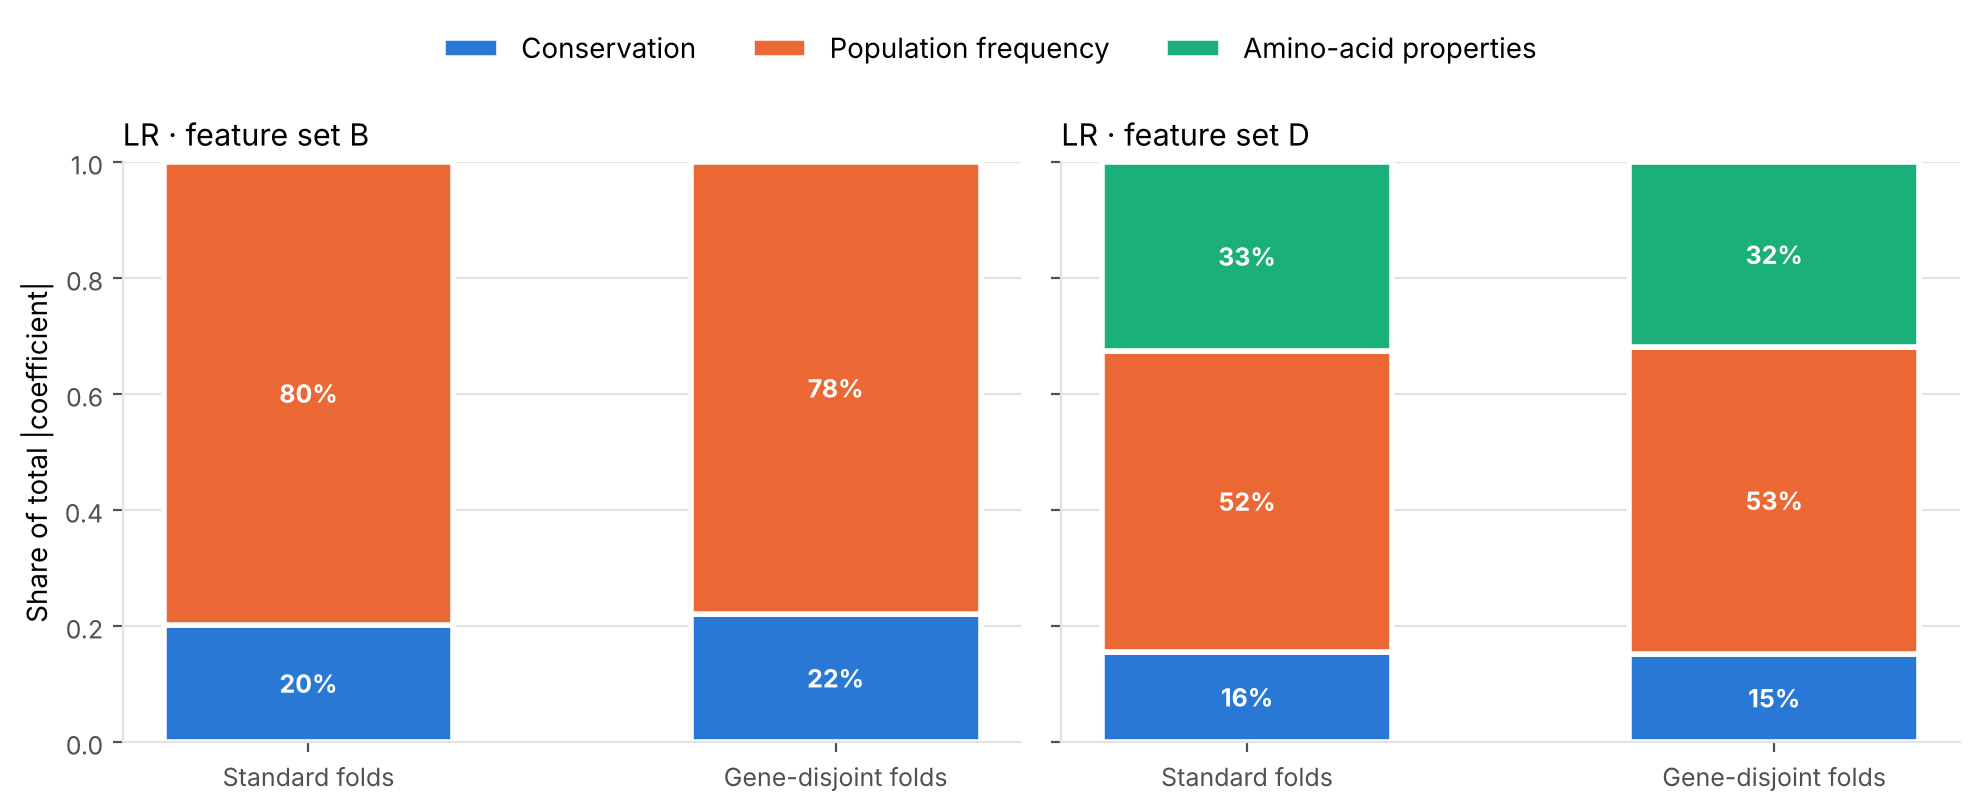

In [14]:
# Figure 2: family share of |weights|
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, fs in zip(axes, ["B", "D"]):
    fams = [f for f in ["conservation", "population", "amino_acid"]
            if ((fam_sum.feature_set == fs) & (fam_sum.family == f)).any()]
    for j, val in enumerate(["standard", "gene_disjoint"]):
        bottom = 0
        for fam in fams:
            r = fam_sum[(fam_sum.validation == val) & (fam_sum.feature_set == fs) & (fam_sum.family == fam)].iloc[0]
            ax.bar(j, r.share_mean, bottom=bottom, width=0.55, color=FAMILY_COLORS[fam], edgecolor="white",
                   linewidth=2, label=FAMILY_NAMES[fam] if (val == "standard" and fs == "D") else None)
            if r.share_mean > 0.06:
                ax.text(j, bottom + r.share_mean / 2, f"{r.share_mean:.0%}", ha="center", va="center",
                        color="white", fontsize=9, fontweight="bold")
            bottom += r.share_mean
    ax.set_xticks([0, 1])
    ax.set_xticklabels([SCHEME_NAMES["standard"], SCHEME_NAMES["gene_disjoint"]])
    ax.set_title(f"LR · feature set {fs}", fontsize=11, loc="left")
    ax.set_ylim(0, 1)
    style(ax)
axes[0].set_ylabel("Share of total |coefficient|")
fig.legend(loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIGS / "fig2_family_weight_share.png", dpi=200)
plt.show()

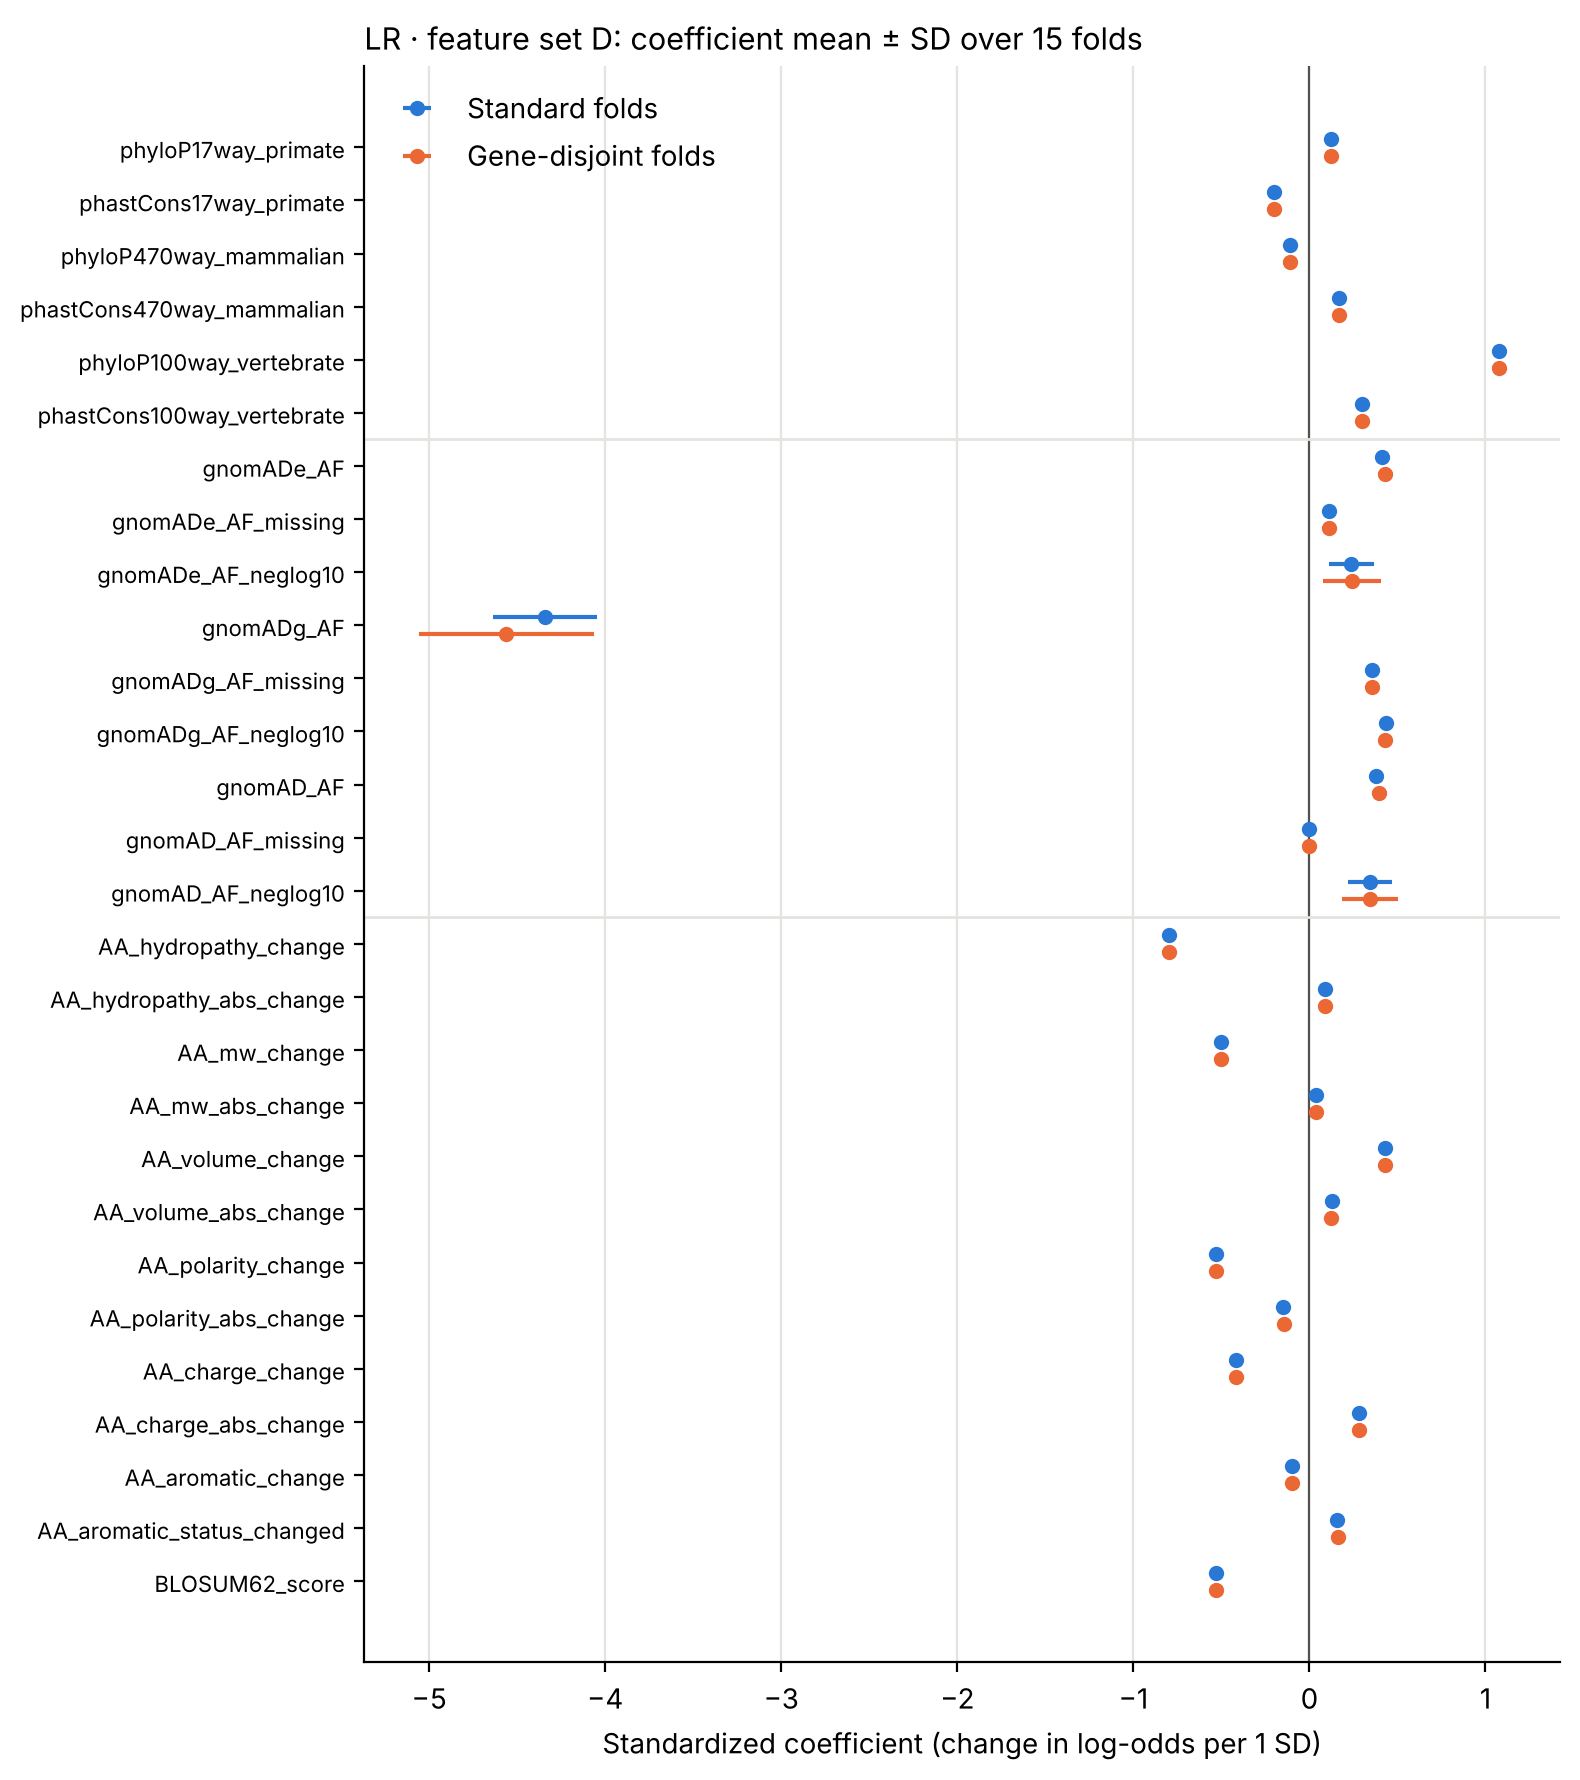

In [15]:
# Figure 3: per-feature weights for set D
d = feat_df[feat_df.feature_set == "D"]
fig, ax = plt.subplots(figsize=(8, 9))
for j, val in enumerate(["standard", "gene_disjoint"]):
    s = d[d.validation == val].set_index("feature").loc[feat_order]
    y = np.arange(len(feat_order)) + (j - 0.5) * 0.32
    ax.errorbar(s.mean_coef, y, xerr=s.sd_coef, fmt="o", ms=4.5, color=SCHEME_COLORS[val],
                ecolor=SCHEME_COLORS[val], elinewidth=1.5, capsize=0, label=SCHEME_NAMES[val])
ax.axvline(0, color=INK2, linewidth=0.8)
ax.set_yticks(range(len(feat_order)))
ax.set_yticklabels(feat_order, fontsize=8)
ax.invert_yaxis()
n_cons = len(cfg["feature_groups"]["conservation"])
n_pop = len(cfg["feature_groups"]["population"])
for edge in (n_cons, n_cons + n_pop):
    ax.axhline(edge - 0.5, color=GRID, linewidth=1)
ax.set_xlabel("Standardized coefficient (change in log-odds per 1 SD)")
ax.set_title("LR · feature set D: coefficient mean ± SD over 15 folds", fontsize=11, loc="left")
for s_ in ["top", "right"]:
    ax.spines[s_].set_visible(False)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / "fig3_coefficients_setD.png", dpi=200)
plt.show()

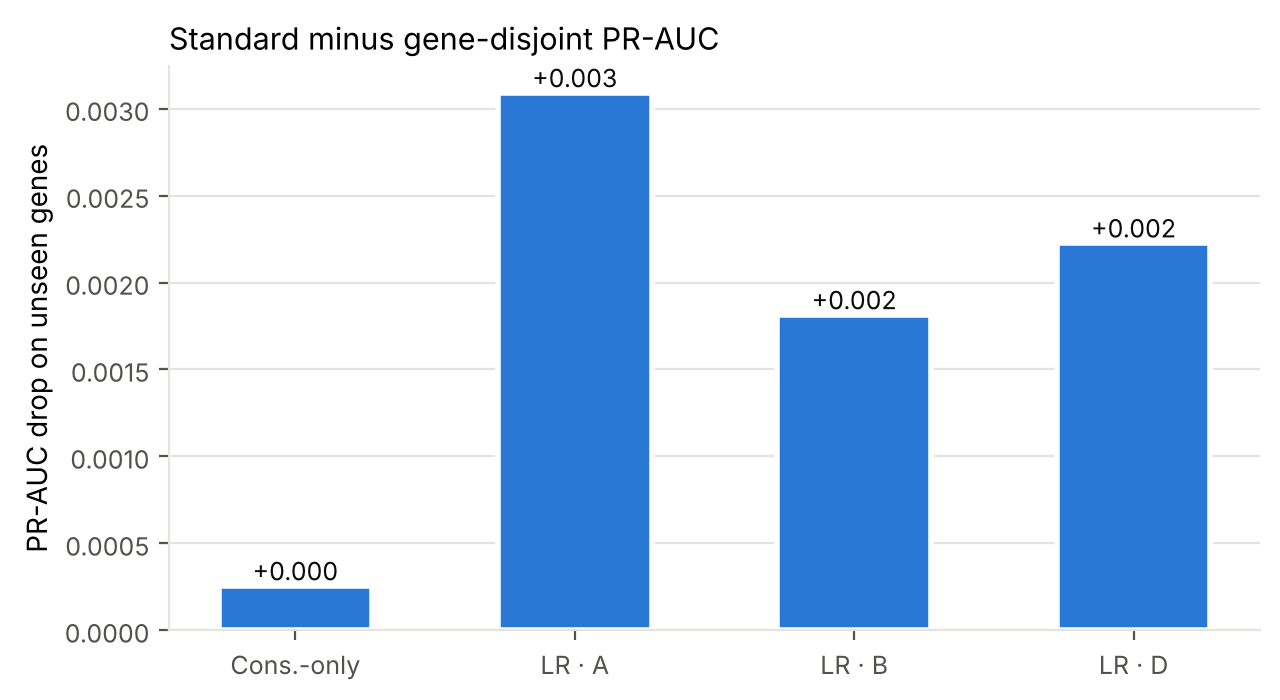

In [16]:
# Figure 4: PR-AUC drop from standard to gene-disjoint folds
g = gap[gap.metric == "pr_auc"].set_index(["model", "feature_set"])
labs = [lab for *_, lab in MODELS[1:]]
vals = [g.loc[(mod, fs), "gap"] for mod, fs, _ in MODELS[1:]]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(range(len(vals)), vals, width=0.55, color="#2a78d6", edgecolor="white", linewidth=2)
for i, v in enumerate(vals):
    ax.text(i, v, f"{v:+.3f}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(labs)
ax.set_ylabel("PR-AUC drop on unseen genes")
ax.set_title("Standard minus gene-disjoint PR-AUC", fontsize=11, loc="left")
style(ax)
fig.tight_layout()
fig.savefig(FIGS / "fig4_prauc_gap.png", dpi=200)
plt.show()

## 10. Supplementary: threshold chosen on training data

The team default stays at 0.5. Balanced class weights push Logistic Regression toward calling variants pathogenic, so at
0.5 the accuracy on set A is only just above the majority baseline. As a check, each fold here also gets a threshold
picked on its own training rows only. I take out-of-fold predictions from the same inner CV, with that fold's chosen
hyperparameters, and pick the cut-off that maximizes MCC. That cut-off is then applied unchanged to the test fold.
These predictions are saved to a separate file and do not replace the shared one.

In [17]:
T_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)


def best_threshold(y, p):
    return float(T_GRID[int(np.argmax([matthews_corrcoef(y, (p >= t).astype(int)) for t in T_GRID]))])


def tuned_fold(validation, repeat, fold, path):
    warnings.filterwarnings("ignore")
    df = fold_frames[(validation, repeat)]
    det = details[(details.validation == validation) & (details.repeat == repeat) & (details.fold == fold)]
    is_test = df.test_fold.values == fold
    train, test = df[~is_test], df[is_test]
    y_tr = train.label.values
    cv = inner_cv(validation, repeat, fold)
    groups = train.GeneSymbol.values if validation == "gene_disjoint" else None
    out = []
    track = det[det.model == "ConservationOnly"].chosen_track.iloc[0]
    cons = make_cons_pipeline()
    oof = cross_val_predict(cons, train[[track]], y_tr, cv=cv, groups=groups, method="predict_proba")[:, 1]
    thr = best_threshold(y_tr, oof)
    p = cons.fit(train[[track]], y_tr).predict_proba(test[[track]])[:, 1]
    f = pred_frame("ConservationOnly", "A", validation, repeat, fold, test, p)
    f["pred_label"], f["threshold"] = (p >= thr).astype(int), thr
    out.append(f)
    for fs in FEATURE_SETS:
        cols = cfg["feature_sets"][fs]
        r = det[(det.model == "LogisticRegression") & (det.feature_set == fs)].iloc[0]
        pipe = make_lr_pipeline().set_params(lr__solver="lbfgs" if r.best_penalty == "l2" else "saga",
                                             lr__C=float(r.best_C), lr__l1_ratio=float(r.best_l1_ratio))
        oof = cross_val_predict(clone(pipe), train[cols], y_tr, cv=cv, groups=groups, method="predict_proba")[:, 1]
        thr = best_threshold(y_tr, oof)
        p = pipe.fit(train[cols], y_tr).predict_proba(test[cols])[:, 1]
        f = pred_frame("LogisticRegression", fs, validation, repeat, fold, test, p)
        f["pred_label"], f["threshold"] = (p >= thr).astype(int), thr
        out.append(f)
    res = pd.concat(out, ignore_index=True)
    res.to_pickle(path)
    return res


tjobs = [(v, int(r), int(f), CACHE / "tuned" / f"{v}_r{r}_f{f}.pkl")
         for v, r, f in details[["validation", "repeat", "fold"]].drop_duplicates().itertuples(index=False)]
todo = [j for j in tjobs if not j[3].exists()]
print(f"{len(todo)} of 30 folds still to run")
Parallel(n_jobs=N_JOBS)(delayed(tuned_fold)(*j) for j in todo)
tuned = pd.concat([pd.read_pickle(j[3]) for j in tjobs], ignore_index=True)
tuned = tuned.sort_values(["model", "feature_set", "validation", "repeat", "fold", "VariationID"])
tuned.to_csv(RESULTS / "sharan_lr_baseline_predictions_tuned_threshold.csv.gz", index=False)


def cls_metrics(g):
    y, yhat = g.label.values, g.pred_label.values
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return pd.Series({"accuracy": (tp + tn) / len(y), "mcc": matthews_corrcoef(y, yhat),
                      "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp)})


a = preds[preds.model != "Majority"].groupby(KEYS).apply(cls_metrics, include_groups=False).add_suffix("_at_0.5")
b = tuned.groupby(KEYS).apply(cls_metrics, include_groups=False).add_suffix("_tuned")
thr = tuned.groupby(KEYS).threshold.first().rename("tuned_threshold")
tt = pd.concat([thr, a, b], axis=1).reset_index()
tt.to_csv(RESULTS / "tuned_threshold_metrics.csv", index=False)
tts = tt.groupby(["validation", "model", "feature_set"]).mean(numeric_only=True).drop(columns=["repeat", "fold"])
tts.to_csv(RESULTS / "tuned_threshold_summary.csv")
tts.round(3)

30 of 30 folds still to run


tuned_threshold  accuracy_at_0.5  mcc_at_0.5  sensitivity_at_0.5  specificity_at_0.5  accuracy_tuned  mcc_tuned  sensitivity_tuned  specificity_tuned
validation    model              feature_set                                                                                                                                                       
gene_disjoint ConservationOnly   A                      0.559            0.725       0.427               0.739               0.720           0.742      0.432              0.689              0.766
              LogisticRegression A                      0.579            0.712       0.423               0.774               0.685           0.741      0.433              0.695              0.762
                                 B                      0.591            0.763       0.519               0.820               0.738           0.784      0.522              0.741              0.804
                                 D                      0.579            0.800       0.585               0.844               0.782           0.814      0.588              0.789              0.826
standard      ConservationOnly   A                      0.545            0.725       0.428               0.739               0.719           0.740      0.434              0.701              0.757
              LogisticRegression A                      0.583            0.712       0.425               0.775               0.685           0.743      0.437              0.696              0.764
                                 B                      0.595            0.764       0.520               0.821               0.738           0.786      0.523              0.737              0.808
                                 D                      0.573            0.801       0.587               0.844               0.783           0.814      0.589              0.793              0.823

## 11. Context: published tools on the same variants

The project dataset also carries scores from published predictors. They are not used for training. The scores below are
computed over every variant that has a value. This is not a fair head-to-head. These tools use much richer inputs, and
many of these ClinVar variants were probably in their training data or used to tune them (the circularity problem
described by Grimm et al., 2015). Read it as a rough ceiling.

In [18]:
if PROJECT_CSV.exists():
    proj = pd.read_csv(PROJECT_CSV, usecols=["VariationID", "label", "REVEL_score", "AM_score",
                                             "CADD_PHRED_score", "EVE_score", "PrimateAI_score"])
    rows = []
    for c, name in [("REVEL_score", "REVEL"), ("AM_score", "AlphaMissense"), ("EVE_score", "EVE"),
                    ("CADD_PHRED_score", "CADD"), ("PrimateAI_score", "PrimateAI")]:
        s = proj[["label", c]].dropna()
        rows.append({"tool": name, "variants_scored": len(s), "roc_auc": roc_auc_score(s.label, s[c]),
                     "pr_auc": average_precision_score(s.label, s[c]), "pathogenic_share": s.label.mean()})
    for fs in FEATURE_SETS:
        r = summ[(summ.validation == "gene_disjoint") & (summ.model == "LogisticRegression") & (summ.feature_set == fs)].iloc[0]
        rows.append({"tool": f"My LR, set {fs} (gene-disjoint, fold mean)", "variants_scored": len(data),
                     "roc_auc": r.roc_auc_mean, "pr_auc": r.pr_auc_mean, "pathogenic_share": data.label.mean()})
    tools = pd.DataFrame(rows).sort_values("roc_auc", ascending=False)
    tools.to_csv(RESULTS / "published_tool_comparison.csv", index=False)
    display(tools.round(3))
else:
    print("project dataset not found, skipping")

,tool,variants_scored,roc_auc,pr_auc,pathogenic_share
0,REVEL,42143,0.947,0.901,0.309
1,AlphaMissense,43133,0.920,0.841,0.310
7,"My LR, set D (gene-disjoint, fold mean)",46012,0.891,0.770,0.304
2,EVE,30278,0.889,0.824,0.368
3,CADD,46012,0.887,0.754,0.304
6,"My LR, set B (gene-disjoint, fold mean)",46012,0.861,0.718,0.304
5,"My LR, set A (gene-disjoint, fold mean)",46012,0.796,0.588,0.304
4,PrimateAI,45502,0.767,0.539,0.304


## 12. What the results say

- **H1, feature families on unseen genes.** Each family adds real signal. On gene-disjoint folds, adding population
  frequency (A to B) raises PR-AUC by about 0.13, and adding amino-acid properties (B to D) adds about 0.05 more. Both
  gains show up in all 15 folds and pass the corrected t-test. The full model reaches ROC-AUC 0.89, PR-AUC 0.77 and MCC 0.59.
- **H2, label echo.** Logistic Regression shows no sign of it. The population-frequency gain is the same on standard and
  gene-disjoint folds, and the family's share of the weights hardly moves (about 80% vs 78% in set B). The weights do get
  less stable on unseen genes: the SD of the `gnomADg_AF` weight roughly triples. A linear model on these features has no
  way to memorise genes, so a small gap is expected here. The more flexible models are where H2 has room to appear.
- **Baselines.** On conservation features alone, Logistic Regression barely improves on just using `phyloP100way_vertebrate`
  (picked in every fold). Combining the six tracks adds very little.
- **Threshold.** At 0.5 the model favours sensitivity. A cut-off picked on training data (around 0.57 to 0.60) adds 1.5 to 3
  points of accuracy but leaves MCC almost unchanged, so 0.5 stays the reported default.